# CODE 5.3: Time per Photo

> **Goal:** measure how long PatchCore and YOLO need to judge one photo, measured the same way for both: from reading the crop file to the score. A camera on a production line sends one photo at a time, so the photos are judged one by one.
>
> - **Input:**
>   - the crops of notebook 3.1, and the test photos of split 1
>   - PatchCore of split 1: the pretrained network (as in notebook 4.1) and `models/patchcore/split_1_memory_bank.npz`
>   - YOLO of split 1 with k = 40: `models/yolo/split_1_k40/weights/last.pt` (notebook 4.2)
>   - the saved scores of notebooks 4.1 and 4.3, to check that the timed code gives the same scores
> - **Output:** nothing is saved. The times are printed and drawn.

### How the Time Is Measured

> - **Same photos:** the 150 test photos of split 1, for both models.
> - **Same start and end:** the clock starts before the crop file is read and stops when the score is ready. Comparing the score with the limit (PASS or REJECT) takes almost no time, so it is left out.
> - **One photo at a time,** like a camera on a production line.
> - **Warm-up:** the first photos are always slower, because the GPU and the libraries prepare themselves. So a few photos are judged first and not counted.
> - **Wait for the GPU:** the GPU works in the background, so before the clock stops we wait until it is really done (`torch.cuda.synchronize()`). Without this, the GPU would look faster than it is.
> - **Median:** the middle time of all timed photos. One slow photo (for example when Windows does something else at that moment) hardly moves it. The **90th percentile** shows the slow side: 9 of 10 photos are faster than this.
> - **GPU and CPU:** a factory computer may not have a GPU, so both models are also timed on the CPU, with fewer photos because it is much slower.
> - **One model of each kind:** PatchCore and YOLO with k = 40, both of split 1. The other splits and k values use a network and a memory bank of the same size, so they need the same time.

### Words Used in This Notebook

> - **Millisecond (ms):** a thousandth of a second. 20 ms per photo means 50 photos per second.
> - **Warm-up:** photos judged before the clock is used.
> - **Lambda:** `lambda rel_path: ...` is a small function written in one line. Here it means "judge this photo with this model on this device", so one timing function can time every model.

## Import Libraries & Variables

### Import Libraries

> - The first line saves figures as JPEG, so the notebook file stays small.
> - `os`: works with folders and file paths. `logging`: sets how much Ultralytics prints. `time`: the clock (`time.perf_counter()`, the most exact clock in Python).
> - `numpy`, `pandas`: work with numbers and tables.
> - `matplotlib`: draws the figure.
> - `PIL` (Pillow): opens the crops for PatchCore.
> - `torch`, `F`, `wide_resnet50_2`, `Wide_ResNet50_2_Weights`, `create_feature_extractor`: PatchCore's network, exactly as in notebook 4.1.
> - `YOLO`, `LOGGER`: Ultralytics, as in notebook 4.3.
> - `tqdm`: shows a progress bar.

In [1]:
%config InlineBackend.figure_formats = ["jpeg"]

import os
import logging
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn.functional as F
from torchvision.models import Wide_ResNet50_2_Weights, wide_resnet50_2
from torchvision.models.feature_extraction import create_feature_extractor
from ultralytics import YOLO
from ultralytics.utils import LOGGER
from tqdm import tqdm

### Variables

#### Folder Paths

> This code finds the main project folder. It starts in the folder of this notebook and goes up until it finds the `data` folder, so the paths work wherever the notebook is.
>
> - `CROP_DIR`: the crops (notebook 3.1).
> - `PATCHCORE_RESULTS_DIR`, `YOLO_RESULTS_DIR`: the saved scores of notebooks 4.1 and 4.3.
> - `BANK_FILE`: the memory bank of PatchCore, split 1 (notebook 4.1).
> - `YOLO_FILE`: the YOLO model of split 1 with k = 40 (notebook 4.2).
>
> If a model file is missing, the code stops with a message that says what to do.

In [2]:
ROOT_DIR = os.getcwd()
while not os.path.isdir(os.path.join(ROOT_DIR, "data")) and ROOT_DIR != os.path.dirname(ROOT_DIR):
    ROOT_DIR = os.path.dirname(ROOT_DIR)

CROP_DIR = os.path.join(ROOT_DIR, "data", "processed", "crops")
PATCHCORE_RESULTS_DIR = os.path.join(ROOT_DIR, "results", "patchcore")
YOLO_RESULTS_DIR = os.path.join(ROOT_DIR, "results", "yolo")
BANK_FILE = os.path.join(ROOT_DIR, "models", "patchcore", "split_1_memory_bank.npz")
YOLO_FILE = os.path.join(ROOT_DIR, "models", "yolo", "split_1_k40", "weights", "last.pt")

if not os.path.exists(BANK_FILE):
    raise FileNotFoundError("models/patchcore/split_1_memory_bank.npz not found. Run notebook 4.1 first.")
if not os.path.exists(YOLO_FILE):
    raise FileNotFoundError("models/yolo/split_1_k40/weights/last.pt not found. Run notebook 4.2 first.")
print("Project folder found:", os.path.basename(ROOT_DIR))

Project folder found: visual-defect-inspection


#### Settings

> - `SPLIT`, `K`: the two timed models are PatchCore of split 1 and YOLO of split 1 with k = 40.
> - `SHRINK`, `LAYERS`, `NEIGHBOURHOOD`, `CHUNK_ROWS`, `IMAGENET_MEAN`, `IMAGENET_STD`: PatchCore's settings, the same as in notebook 4.1.
> - `IMAGE_SIZE`, `MIN_CONFIDENCE`, `MAX_BOXES`: YOLO's settings, the same as in notebook 4.3.
> - `GPU_WARM_UP`, `CPU_WARM_UP`: how many photos are judged first and not counted.
> - `CPU_PHOTOS`: on the CPU, only the first 20 test photos are timed, because it is much slower.

In [3]:
SPLIT = 1
K = 40
SHRINK = 2
LAYERS = ["layer2", "layer3"]
NEIGHBOURHOOD = 3
CHUNK_ROWS = 4096
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]
IMAGE_SIZE = 928
MIN_CONFIDENCE = 0.0
MAX_BOXES = 20
GPU_WARM_UP = 10
CPU_WARM_UP = 3
CPU_PHOTOS = 20

#### GPU and CPU

> - `DEVICES`: the GPU (`cuda`) if PyTorch can use it, and always the CPU.
> - As in notebook 4.1, the faster but less exact TF32 format is switched off and the calculations are deterministic, so PatchCore gives exactly the same kind of numbers as there. Both models then calculate in full precision.
> - `LOGGER.setLevel(logging.WARNING)`: Ultralytics only prints warnings and errors, as in notebook 4.3.

In [4]:
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
LOGGER.setLevel(logging.WARNING)

DEVICES = (["cuda"] if torch.cuda.is_available() else []) + ["cpu"]
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")
print("CPU threads used by PyTorch:", torch.get_num_threads())

GPU: NVIDIA GeForce RTX 5070 Laptop GPU
CPU threads used by PyTorch: 20


## Functions

### Paths

> `full_path()` turns a path from a table, written with `/`, into a real path on this computer (as in the earlier notebooks).

In [5]:
def full_path(base_dir, rel_path):
    return os.path.join(base_dir, *rel_path.split("/"))

### Load One Photo for PatchCore

> `load_photo()` does what `load_batch()` did in notebook 4.1, for one photo: open the crop, make it `shrink` times smaller, scale the colours like ImageNet, and move it to the `device`. The result is a batch of one photo.

In [6]:
def load_photo(rel_path, shrink, device):
    crop = Image.open(full_path(CROP_DIR, rel_path)).convert("RGB")
    small = crop.resize((crop.width // shrink, crop.height // shrink), Image.BOX)
    picture = torch.from_numpy(np.asarray(small, dtype=np.float32) / 255).permute(2, 0, 1)[None]
    mean = torch.tensor(IMAGENET_MEAN).view(1, 3, 1, 1)
    std = torch.tensor(IMAGENET_STD).view(1, 3, 1, 1)
    return ((picture - mean) / std).to(device)

### Patch Features

> `patch_features()` is the same function as in notebook 4.1: one feature per patch, from `layer2` and `layer3`, each averaged with its neighbours.

In [7]:
@torch.no_grad()
def patch_features(extractor, batch, layers, neighbourhood):
    maps = extractor(batch)
    grid_size = maps[layers[0]].shape[-2:]
    pooled = []
    for name in layers:
        averaged = F.avg_pool2d(maps[name], neighbourhood, stride=1, padding=neighbourhood // 2)
        pooled.append(F.interpolate(averaged, size=grid_size, mode="bilinear", align_corners=False))
    return torch.cat(pooled, dim=1).permute(0, 2, 3, 1)

### Nearest Distances

> `nearest_distances()` is the same function as in notebook 4.1: for every patch feature, the distance to its nearest feature in the memory bank, `chunk_rows` patches at a time.

In [8]:
@torch.no_grad()
def nearest_distances(queries, bank, chunk_rows):
    distances, indices = [], []
    for start in range(0, len(queries), chunk_rows):
        nearest = torch.cdist(queries[start:start + chunk_rows], bank).min(dim=1)
        distances.append(nearest.values)
        indices.append(nearest.indices)
    return torch.cat(distances), torch.cat(indices)

### PatchCore's Score of One Photo

> `patchcore_score()` judges one photo with PatchCore: load it, get its patch features, find the nearest memory bank feature of every patch, and return the largest distance, the photo's score. `.item()` brings that one number back from the GPU.

In [9]:
def patchcore_score(rel_path, extractor, bank, device):
    batch = load_photo(rel_path, shrink=SHRINK, device=device)
    features = patch_features(extractor, batch, layers=LAYERS, neighbourhood=NEIGHBOURHOOD)
    distances, _ = nearest_distances(features.reshape(-1, features.shape[-1]), bank, chunk_rows=CHUNK_ROWS)
    return distances.max().item()

### YOLO's Score of One Photo

> `yolo_score()` judges one photo with YOLO, exactly as in notebook 4.3: predict with the same settings and return the highest confidence of its boxes. YOLO reads the crop file itself.

In [10]:
def yolo_score(model, rel_path, device):
    result = model.predict(full_path(CROP_DIR, rel_path), imgsz=IMAGE_SIZE, conf=MIN_CONFIDENCE,
                           max_det=MAX_BOXES, device=device, verbose=False)[0]
    return float(result.boxes.conf.max()) if len(result.boxes) else 0.0

### Time Many Photos

> `time_photos()` gets `score_one`, a function that judges one photo, and the photos to time:
>
> 1. Judge the first `warm_up` photos without the clock.
> 2. For every photo: wait until the GPU is free, start the clock, judge the photo, wait until the GPU is done, stop the clock. On the CPU there is nothing to wait for.
>
> It returns the scores and the time of every photo in milliseconds.

In [11]:
def time_photos(score_one, rel_paths, warm_up, device, desc):
    for rel_path in rel_paths[:warm_up]:
        score_one(rel_path)
    scores, milliseconds = [], []
    for rel_path in tqdm(rel_paths, desc=desc):
        if device == "cuda":
            torch.cuda.synchronize()
        start = time.perf_counter()
        scores.append(score_one(rel_path))
        if device == "cuda":
            torch.cuda.synchronize()
        milliseconds.append(1000 * (time.perf_counter() - start))
    return np.array(scores), np.array(milliseconds)

## Load Data

### The Test Photos and Their Saved Scores

> - `test_photos`: the crops of the 150 test photos of split 1, in the order of PatchCore's score file.
> - `saved_scores`: the scores of both models for these photos, as saved by notebooks 4.1 and 4.3 (YOLO with k = 40), in the same order. They are only used to check that the timed code is the same code.

In [12]:
patchcore_saved = pd.read_csv(os.path.join(PATCHCORE_RESULTS_DIR, f"split_{SPLIT}_scores.csv"))
patchcore_saved = patchcore_saved[patchcore_saved["part"] == "test"]
yolo_saved = pd.read_csv(os.path.join(YOLO_RESULTS_DIR, f"split_{SPLIT}_scores.csv"))
yolo_saved = yolo_saved[(yolo_saved["part"] == "test") & (yolo_saved["k"] == K)].set_index("crop_image")

test_photos = patchcore_saved["crop_image"].tolist()
saved_scores = {"PatchCore": patchcore_saved["score"].to_numpy(),
                f"YOLO k = {K}": yolo_saved.loc[test_photos, "score"].to_numpy()}
print(f"Test photos of split {SPLIT}: {len(test_photos)}")

Test photos of split 1: 150


### Load the Models on Every Device

> For the GPU and for the CPU, each gets its own copy of both models, so no model has to move between them while the clock runs:
>
> - PatchCore: the pretrained network cut after `layer3` (as in notebook 4.1), and the memory bank. The memory bank was saved in half precision; it is turned back into normal precision, as in notebook 4.1.
> - YOLO: the trained model of split 1 with k = 40.
>
> Loading takes a few seconds, but it happens only once, when the inspection program starts, so it is not part of the time per photo.

In [13]:
weights = Wide_ResNet50_2_Weights.IMAGENET1K_V1
with np.load(BANK_FILE) as bank_file:
    bank_features = bank_file["features"].astype(np.float32)

extractors, banks, yolo_models = {}, {}, {}
for device in DEVICES:
    backbone = wide_resnet50_2(weights=weights).eval().to(device)
    extractors[device] = create_feature_extractor(backbone, return_nodes={name: name for name in LAYERS})
    banks[device] = torch.from_numpy(bank_features).to(device)
    yolo_models[device] = YOLO(YOLO_FILE)
print(f"Memory bank: {bank_features.shape[0]:,} patch features of {bank_features.shape[1]:,} numbers")
print("Models loaded on:", ", ".join(device.upper() for device in DEVICES))

Memory bank: 7,648 patch features of 1,536 numbers
Models loaded on: CUDA, CPU


## Step 1: Time Both Models

### Judge the Test Photos and Measure the Time

> For every device and both models: `time_photos()` with a lambda that judges one photo with that model on that device. On the GPU all 150 test photos are timed, on the CPU the first `CPU_PHOTOS`.
>
> `times` gets one row per model and device: the number of timed photos, the median and the 90th percentile in milliseconds, and how many photos per second that makes (1000 divided by the median).

In [14]:
time_rows, timed_scores = [], {}
for device in DEVICES:
    photos = test_photos if device == "cuda" else test_photos[:CPU_PHOTOS]
    warm_up = GPU_WARM_UP if device == "cuda" else CPU_WARM_UP
    judges = {"PatchCore": lambda rel_path: patchcore_score(rel_path, extractors[device], banks[device], device),
              f"YOLO k = {K}": lambda rel_path: yolo_score(yolo_models[device], rel_path, device)}
    for model_name, score_one in judges.items():
        scores, milliseconds = time_photos(score_one, photos, warm_up=warm_up, device=device,
                                           desc=f"{model_name} on the {device.upper()}")
        timed_scores[(model_name, device)] = scores
        time_rows.append({"model": model_name, "device": "GPU" if device == "cuda" else "CPU",
                          "photos timed": len(photos), "median (ms)": np.median(milliseconds),
                          "90th percentile (ms)": np.percentile(milliseconds, 90),
                          "photos per second": 1000 / np.median(milliseconds)})
times = pd.DataFrame(time_rows)
times.round(1)

YOLO k = 40 on the CPU: 100%|██████████| 20/20 [00:02<00:00,  9.12it/s]


,model,device,photos timed,median (ms),90th percentile (ms),photos per second
0,PatchCore,GPU,150,49.3,50.7,20.3
1,YOLO k = 40,GPU,150,30.5,34.3,32.7
2,PatchCore,CPU,20,153.1,182.2,6.5
3,YOLO k = 40,CPU,20,105.8,117.1,9.4


> **What we see** (in the progress bars, CUDA means the GPU):
>
> - **On the GPU**, YOLO judges a photo in 30.5 ms (median) and PatchCore in 49.3 ms. YOLO is about 1.6 times faster: 32.7 against 20.3 photos per second.
> - **On the CPU** (20 threads), YOLO needs 105.8 ms and PatchCore 153.1 ms: 9.4 and 6.5 photos per second.
> - The 90th percentiles are close to the medians, so the times are stable from photo to photo.
> - For a line that needs, for example, 10 photos per second, both models are fast enough on the GPU. On the CPU, neither quite reaches it.

### Same Scores as Before?

> The timed code must be the same code as in notebooks 4.1 and 4.3, otherwise we would time something else. So the scores of the timed photos are compared with the saved scores: the largest difference per model and device. Tiny differences in the last digits are normal: the GPU and the CPU round a little differently, and notebook 4.1 judged 8 photos at a time instead of one.

In [15]:
for (model_name, device), scores in timed_scores.items():
    difference = np.abs(scores - saved_scores[model_name][:len(scores)]).max()
    print(f"{model_name} on the {device.upper()}: largest difference to the saved scores {difference:.2g} "
          f"(scores from {scores.min():.3g} to {scores.max():.3g})")

PatchCore on the CUDA: largest difference to the saved scores 5.5e-06 (scores from 1.88 to 3.63)
YOLO k = 40 on the CUDA: largest difference to the saved scores 0.0011 (scores from 0.000104 to 0.949)
PatchCore on the CPU: largest difference to the saved scores 1.1e-05 (scores from 1.95 to 3.63)
YOLO k = 40 on the CPU: largest difference to the saved scores 0.0011 (scores from 0.00284 to 0.949)


> **What we see:**
>
> - **PatchCore:** the largest difference is 5.5e-06 on the GPU and 1.1e-05 on the CPU, for scores from 1.88 to 3.63. That is only rounding.
> - **YOLO:** the largest difference is 0.0011 on both devices, for scores up to 0.949. That both devices give the same difference suggests that the saved scores of notebook 4.3 are the ones that differ a little. Notebook 4.3 ran YOLO with PyTorch's usual GPU settings, which probably allow the faster TF32 number format in some calculations; this notebook switches TF32 off, as notebook 4.1 did.
> - Both differences are tiny compared with the scores, so the timed code is the same code as in notebooks 4.1 and 4.3.

### Time per Photo in a Figure

> The median time per photo of both models, one panel per device. PatchCore is orange and YOLO is blue, as in notebook 5.1.

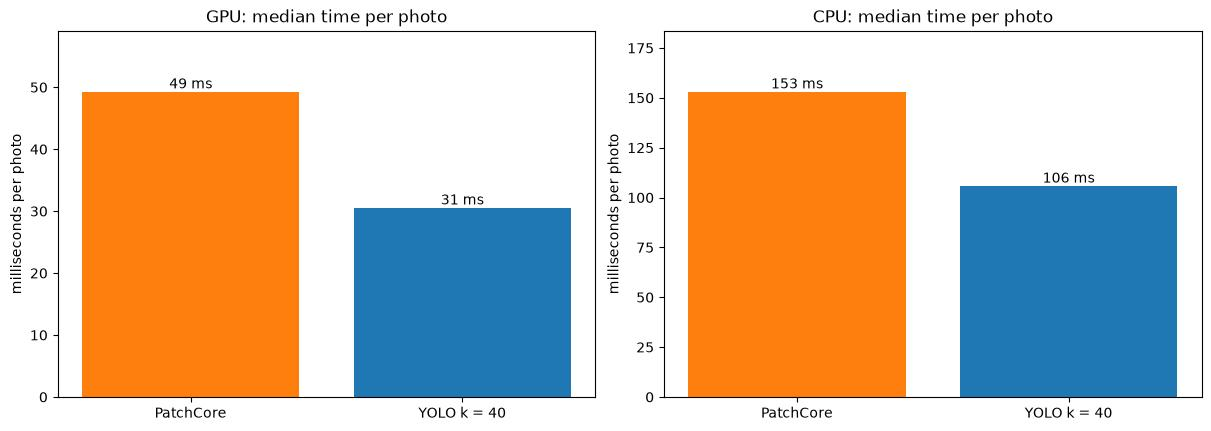

In [16]:
device_names = times["device"].unique()
fig, axes = plt.subplots(1, len(device_names), figsize=(6 * len(device_names), 4.2), layout="constrained", squeeze=False)
for ax, device_name in zip(axes[0], device_names):
    rows = times[times["device"] == device_name]
    bars = ax.bar(rows["model"], rows["median (ms)"], color=["tab:orange", "tab:blue"])
    ax.bar_label(bars, labels=[f"{value:.0f} ms" for value in rows["median (ms)"]])
    ax.set_title(f"{device_name}: median time per photo")
    ax.set_ylabel("milliseconds per photo")
    ax.set_ylim(0, 1.2 * rows["median (ms)"].max())
plt.show()

> **What we see:** on both devices, the orange bar (PatchCore) is higher than the blue one (YOLO). YOLO is about 1.6 times faster on the GPU and about 1.4 times faster on the CPU. The GPU makes both models about 3 times faster than the CPU.

## Summary

> **What this notebook did**
>
> - Timed PatchCore and YOLO (k = 40) of split 1 on the same test photos, one photo at a time, from reading the crop file to the score, on the GPU and on the CPU.
> - Checked that the timed code gives the same scores as notebooks 4.1 and 4.3.
>
> Nothing was saved.
>
> **What we found**
>
> - YOLO is the faster model: 30.5 ms per photo on the GPU against 49.3 ms for PatchCore (32.7 and 20.3 photos per second), and 105.8 ms against 153.1 ms on the CPU.
> - These times include reading the crop file, one photo at a time. The number of labeled photos does not change YOLO's time, because the network is the same size for every k.
>
> **Next:** the demo (step 6).